# Harmonic Analysis, Fourier Transforms, and Convolution

**AI Mathematics · 7. Advanced Topics**

Understand frequency-domain representations and why Fourier analysis is useful for signals, convolution, and CNN intuition.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Represent signals as sums of frequencies.
- Use the discrete Fourier transform with NumPy.
- Connect convolution and multiplication in the frequency domain.

In [1]:
import numpy as np

## 1. Frequencies and Fourier representation
Fourier analysis decomposes a signal into frequency components. Low frequencies often capture slowly varying structure; high frequencies capture rapid changes and fine detail. In images, the frequency content relates to texture, edges, and spatial scale, though interpretation depends on the signal and transform convention.

In [2]:
import numpy as np

n = 128
t = np.arange(n)
signal = np.sin(2*np.pi*5*t/n) + 0.5*np.sin(2*np.pi*18*t/n)
print("signal shape:", signal.shape)
print("first five samples:", signal[:5].round(3))

signal shape: (128,)
first five samples: [0.    0.629 0.962 0.907 0.64 ]


## 2. Discrete Fourier transform (DFT)
The DFT maps a finite sequence to complex frequency coefficients. `np.fft.rfft` is convenient for real-valued input because negative frequencies are redundant under conjugate symmetry. The coefficient magnitudes reveal which frequencies are present; normalization conventions vary.

In [3]:
spectrum = np.fft.rfft(signal)
frequencies = np.fft.rfftfreq(n, d=1.0)
amplitude = 2*np.abs(spectrum)/n
peak_indices = np.argsort(amplitude[1:])[-4:] + 1
print("strong nonzero frequency bins:", sorted(zip(frequencies[peak_indices], amplitude[peak_indices]), key=lambda x: -x[1]))

strong nonzero frequency bins: [(np.float64(0.0390625), np.float64(0.9999999999999999)), (np.float64(0.140625), np.float64(0.5)), (np.float64(0.3125), np.float64(5.014830093062462e-16)), (np.float64(0.234375), np.float64(4.538833088511137e-16))]


## 3. Inverse transform and frequency filtering
The inverse transform reconstructs the original signal when coefficients are preserved. Removing selected frequencies creates a filter; this can denoise some signals but may also remove meaningful information or introduce ringing.

In [4]:
reconstructed = np.fft.irfft(np.fft.rfft(signal), n=n)
print("reconstruction close:", np.allclose(signal, reconstructed))

filtered_spectrum = spectrum.copy()
filtered_spectrum[10:] = 0  # keep only lower positive-frequency bins
filtered = np.fft.irfft(filtered_spectrum, n=n)
print("filtered shape:", filtered.shape)
print("original/filtered MSE:", np.mean((signal-filtered)**2))

reconstruction close: True
filtered shape: (128,)
original/filtered MSE: 0.125


## 4. Convolution theorem
Under common DFT conventions, convolution in the spatial/time domain corresponds to multiplication in the frequency domain, with normalization depending on the definition. This can make large convolutions efficient through FFTs. CNNs usually use local learned kernels; Fourier analysis provides a complementary perspective, not a replacement for spatial reasoning.

In [5]:
x = np.array([1.0, 2.0, 0.0, -1.0])
h = np.array([1.0, 0.5, -0.5])
linear_conv = np.convolve(x, h, mode="full")
# FFT multiplication needs zero-padding to avoid circular wraparound.
n_fft = len(x) + len(h) - 1
fft_conv = np.fft.irfft(np.fft.rfft(x, n_fft) * np.fft.rfft(h, n_fft), n_fft)
print("direct convolution:", linear_conv)
print("FFT convolution close:", np.allclose(linear_conv, fft_conv))

direct convolution: [ 1.   2.5  0.5 -2.  -0.5  0.5]
FFT convolution close: True


## 5. Sampling and aliasing
A sampled signal cannot represent arbitrarily high frequencies. Frequencies above the Nyquist limit fold into lower frequencies, a phenomenon called aliasing. Sampling frequency and anti-alias filtering matter when converting continuous signals or resizing images.

In [6]:
# A high-frequency sine sampled too coarsely can appear as a different lower frequency.
t = np.arange(16)
sampled = np.sin(2*np.pi*7*t/16)
alias_candidate = np.sin(2*np.pi*9*t/16)
print("sample sequences close (up to numerical tolerance):", np.allclose(sampled, -alias_candidate))

sample sequences close (up to numerical tolerance): True


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: a signal in time and frequency

A Fourier transform represents a signal as a combination of sinusoidal frequencies. Peaks in the magnitude spectrum indicate prominent frequency components. For real-valued signals, the discrete Fourier transform has conjugate symmetry, so the one-sided spectrum is often enough for visual inspection.

24_harmonic_analysis_fourier_and_convolutions.ipynb:cell15:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,frequency (Hz),magnitude
10,5.0,1.001
36,18.0,0.483
64,32.0,0.039
5,2.5,0.031
31,15.5,0.025
45,22.5,0.024
48,24.0,0.023
49,24.5,0.023


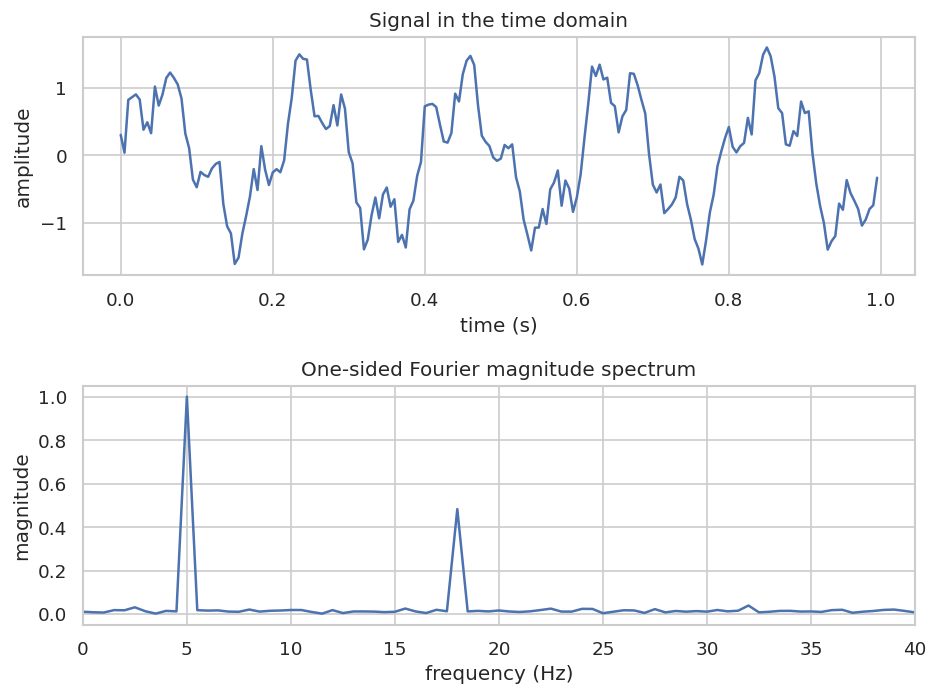

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_fft_fs = 200
viz_fft_t = np.arange(0, 2, 1/viz_fft_fs)
viz_fft_signal = 1.0*np.sin(2*np.pi*5*viz_fft_t) + 0.5*np.sin(2*np.pi*18*viz_fft_t) + 0.15*np.random.default_rng(3).normal(size=viz_fft_t.size)
viz_fft_freq = np.fft.rfftfreq(len(viz_fft_signal), d=1/viz_fft_fs)
viz_fft_amp = 2*np.abs(np.fft.rfft(viz_fft_signal))/len(viz_fft_signal)
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
axes[0].plot(viz_fft_t[:200], viz_fft_signal[:200]); axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("amplitude"); axes[0].set_title("Signal in the time domain")
axes[1].plot(viz_fft_freq, viz_fft_amp); axes[1].set_xlim(0, 40); axes[1].set_xlabel("frequency (Hz)"); axes[1].set_ylabel("magnitude"); axes[1].set_title("One-sided Fourier magnitude spectrum")
plt.tight_layout(); plt.show()
viz_fft_df = pd.DataFrame({"frequency (Hz)": viz_fft_freq, "magnitude": viz_fft_amp}).query("`frequency (Hz)` <= 40").nlargest(8, "magnitude")
display(viz_fft_df.round(3))

### Convolution as a local weighted operation

A one-dimensional convolution combines nearby values using a kernel. A moving-average kernel smooths rapid fluctuations but can blur sharp transitions. In image models, the same idea extends to two-dimensional spatial neighborhoods; kernel orientation and padding conventions matter.

24_harmonic_analysis_fourier_and_convolutions.ipynb:cell17:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
24_harmonic_analysis_fourier_and_convolutions.ipynb:cell17:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


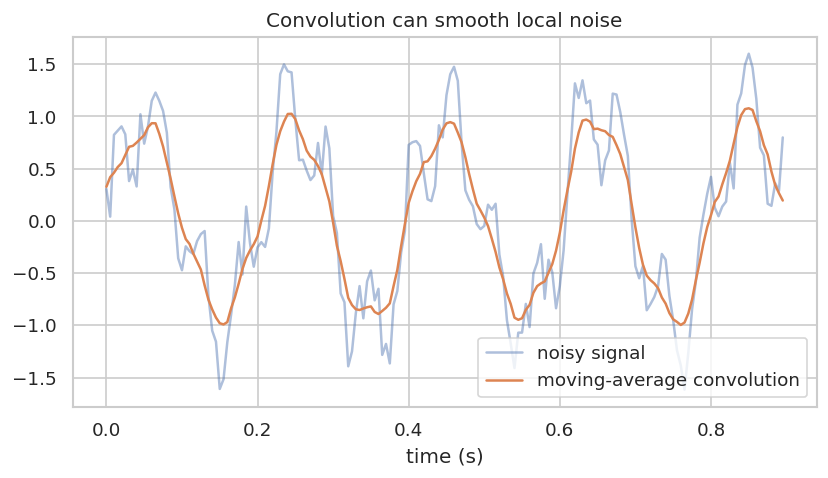

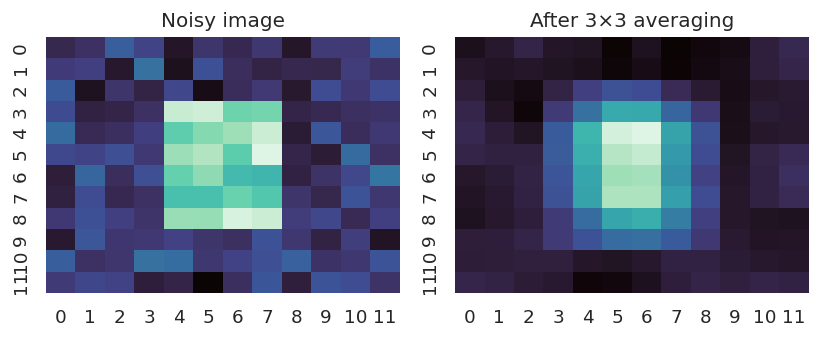

In [8]:
viz_conv_signal = viz_fft_signal[:180]
viz_conv_kernel = np.ones(9)/9
viz_conv_smoothed = np.convolve(viz_conv_signal, viz_conv_kernel, mode="same")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(viz_fft_t[:180], viz_conv_signal, alpha=0.45, label="noisy signal")
ax.plot(viz_fft_t[:180], viz_conv_smoothed, label="moving-average convolution")
ax.set_xlabel("time (s)"); ax.legend(); ax.set_title("Convolution can smooth local noise"); plt.show()

viz_img = np.zeros((12, 12)); viz_img[3:9, 4:8] = 1.0; viz_img += 0.15*np.random.default_rng(4).normal(size=viz_img.shape)
viz_kernel2 = np.ones((3,3))/9
viz_padded = np.pad(viz_img, 1, mode="edge")
viz_img_blur = np.empty_like(viz_img)
for i in range(viz_img.shape[0]):
    for j in range(viz_img.shape[1]):
        viz_img_blur[i,j] = np.sum(viz_padded[i:i+3, j:j+3]*viz_kernel2)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
sns.heatmap(viz_img, cmap="mako", cbar=False, ax=axes[0]); axes[0].set_title("Noisy image")
sns.heatmap(viz_img_blur, cmap="mako", cbar=False, ax=axes[1]); axes[1].set_title("After 3×3 averaging")
plt.tight_layout(); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Reconstruct an arbitrary real vector using rfft and irfft.

In [9]:
x = np.array([0.2, 1.4, -0.3, 2.0, 0.0])
print(np.allclose(x, np.fft.irfft(np.fft.rfft(x), n=len(x))))

True


### Exercise 2
Exercise 2: Compare direct convolution with FFT convolution for short arrays.

In [10]:
x = np.array([1.0, 2.0]); h = np.array([3.0, 4.0])
n = len(x)+len(h)-1
y = np.fft.irfft(np.fft.rfft(x,n)*np.fft.rfft(h,n),n)
print(np.convolve(x,h), y)

[ 3. 10.  8.] [ 3. 10.  8.]


## Key takeaways
- Fourier analysis represents a signal through frequency components.
- FFT-based convolution requires enough zero-padding to reproduce linear rather than circular convolution.
- Sampling rate limits which frequencies can be represented without aliasing.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.